# MPI-INF-3DHP Multi-View 2D-to-3D Pose Lifting

This notebook implements a PyTorch training pipeline for 2D-to-3D human pose estimation
using the MPI-INF-3DHP dataset. It replaces Human3.6M as the training source while keeping
the same deep residual MLP architecture.

## Pipeline:
1. Load `annot.mat` files (no images needed)
2. Project 3D ground truth → 2D using dataset's built-in 2D annotations
3. Train MultiViewLiftingMLP (136 → 51)
4. Stage 2 anatomical fine-tuning
5. Evaluate with MPJPE and PCK


In [1]:
import subprocess, sys

packages = ['torch', 'torchvision', 'numpy', 'scipy']
for pkg in packages:
    print(f"Installing {pkg}...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", pkg, "-q"])
    print(f"  ✓ {pkg}")

import torch
print(f"\nPyTorch: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")


Installing torch...
  ✓ torch
Installing torchvision...
  ✓ torchvision
Installing numpy...
  ✓ numpy
Installing scipy...
  ✓ scipy

PyTorch: 2.11.0+cpu
CUDA Available: False


In [2]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import scipy.io as sio
from collections import defaultdict

print("All imports successful.")
print(f"NumPy: {np.__version__}")
print(f"PyTorch: {torch.__version__}")


All imports successful.
NumPy: 2.4.2
PyTorch: 2.11.0+cpu


In [3]:
# Quick sanity check on one annot.mat file before building the full dataset

BASE_DIR = r'C:\Ahmed\UNI\SEM 8\FYP\FYP--2\Dataset\mpi_inf_3dhp\dataset\mpi'

mat = sio.loadmat(os.path.join(BASE_DIR, 'S1', 'Seq1', 'annot.mat'))

print("Keys:", [k for k in mat.keys() if not k.startswith('__')])

annot2 = mat['annot2']  # (14, 1) — 14 cameras
annot3 = mat['annot3']  # (14, 1) — 14 cameras

print(f"annot2 shape: {annot2.shape}  (cameras x 1)")
print(f"annot3 shape: {annot3.shape}  (cameras x 1)")
print(f"Frames in S1/Seq1: {annot2[0,0].shape[0]:,}")
print(f"2D values per frame: {annot2[0,0].shape[1]}  (28 joints x 2)")
print(f"3D values per frame: {annot3[0,0].shape[1]}  (28 joints x 3)")
print("\n✅ File structure confirmed — ready to build dataset.")


Keys: ['annot2', 'annot3', 'cameras', 'frames', 'univ_annot3']
annot2 shape: (14, 1)  (cameras x 1)
annot3 shape: (14, 1)  (cameras x 1)
Frames in S1/Seq1: 6,416
2D values per frame: 56  (28 joints x 2)
3D values per frame: 84  (28 joints x 3)

✅ File structure confirmed — ready to build dataset.


## Joint Mapping: MPI-INF-3DHP (28 joints) → H3.6M (17 joints)

MPI-INF-3DHP has 28 joints. We map to the same 17 used in Human3.6M so our
model input/output shape stays identical: **136 input → 51 output**.

| Index | Joint Name |
|-------|-----------|
| 0 | Pelvis (root) |
| 1 | Right Hip |
| 2 | Right Knee |
| 3 | Right Ankle |
| 4 | Left Hip |
| 5 | Left Knee |
| 6 | Left Ankle |
| 7 | Spine |
| 8 | Thorax |
| 9 | Neck |
| 10 | Head |
| 11 | Left Shoulder |
| 12 | Left Elbow |
| 13 | Left Wrist |
| 14 | Right Shoulder |
| 15 | Right Elbow |
| 16 | Right Wrist |


In [4]:
# MPI-INF-3DHP → H3.6M compatible 17-joint mapping
MPI_TO_H36M = [14, 8, 7, 6, 9, 10, 11, 15, 12, 13, 16, 5, 4, 3, 20, 21, 22]

class MPIINFDataset(Dataset):
    """
    MPI-INF-3DHP Dataset for multi-view 2D-to-3D pose lifting.
    
    Uses the dataset's own 2D annotations (annot2) from 4 cameras as input X,
    and the 3D annotations (annot3) from camera 0 as ground truth Y.
    
    Output shapes match Human3.6M pipeline exactly:
      X: (N, 136)  — 4 cameras × 17 joints × 2 coords, root-relative
      Y: (N, 51)   — 17 joints × 3 coords, root-relative
    """

    def __init__(self, data_dir: str, subjects: list, num_cams: int = 4, use_cache: bool = True):
        self.data_dir = data_dir
        self.subjects = subjects
        self.num_cams = num_cams
        self.root_joint_idx = 0

        subjects_str = "_".join(map(str, sorted(subjects)))
        self.cache_file = f"mpi_cache_subs_{subjects_str}_cams{num_cams}.pt"

        if use_cache and os.path.exists(self.cache_file):
            print(f"✓ Loaded from cache: {self.cache_file}")
            cached = torch.load(self.cache_file)
            self.X = cached['X']
            self.Y = cached['Y']
            return

        print(f"Processing subjects {subjects} from annot.mat files...")
        X_list, Y_list = [], []

        for s in subjects:
            for seq in [1, 2]:
                mat_path = os.path.join(data_dir, f'S{s}', f'Seq{seq}', 'annot.mat')
                if not os.path.exists(mat_path):
                    print(f"  ⚠ Missing: {mat_path}")
                    continue

                mat = sio.loadmat(mat_path)
                annot2 = mat['annot2']  # (14, 1)
                annot3 = mat['annot3']  # (14, 1)

                num_frames = annot3[0, 0].shape[0]
                print(f"  S{s}/Seq{seq}: {num_frames:,} frames")

                # Get 3D ground truth from camera 0
                gt_3d_all = annot3[0, 0]  # (num_frames, 84)

                for frame in range(num_frames):
                    multi_view_2d = []

                    for cam_idx in range(self.num_cams):
                        # 2D: (num_frames, 56) → reshape to (28, 2)
                        pose_2d_full = annot2[cam_idx, 0][frame].reshape(28, 2).astype(np.float32)
                        pose_2d = pose_2d_full[MPI_TO_H36M]  # → (17, 2)
                        pose_2d_centered = pose_2d - pose_2d[self.root_joint_idx]
                        multi_view_2d.append(pose_2d_centered.reshape(-1))

                    X = np.concatenate(multi_view_2d).astype(np.float32)  # (136,)

                    # 3D ground truth
                    pose_3d_full = gt_3d_all[frame].reshape(28, 3).astype(np.float32)
                    pose_3d = pose_3d_full[MPI_TO_H36M]  # → (17, 3)
                    pose_3d_centered = pose_3d - pose_3d[self.root_joint_idx]
                    Y = pose_3d_centered.reshape(-1).astype(np.float32)  # (51,)

                    X_list.append(X)
                    Y_list.append(Y)

        self.X = torch.tensor(np.array(X_list), dtype=torch.float32)
        self.Y = torch.tensor(np.array(Y_list), dtype=torch.float32)

        if use_cache:
            torch.save({'X': self.X, 'Y': self.Y}, self.cache_file)
            print(f"✓ Saved cache: {self.cache_file}")

        print(f"\nDataset ready: {len(self.X):,} samples")

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]


In [5]:
BASE_DIR = r'C:\Ahmed\UNI\SEM 8\FYP\FYP--2\Dataset\mpi_inf_3dhp\dataset\mpi'

# Standard MPI-INF-3DHP split
# Train: S1-S6  |  Val: S7  |  Unseen Test: S8
print("Loading training set (S1–S6)...")
train_dataset = MPIINFDataset(BASE_DIR, subjects=[1, 2, 3, 4, 5, 6], num_cams=4, use_cache=True)

print("\nLoading validation set (S7)...")
val_dataset = MPIINFDataset(BASE_DIR, subjects=[7], num_cams=4, use_cache=True)

print("\nLoading unseen test set (S8)...")
test_dataset = MPIINFDataset(BASE_DIR, subjects=[8], num_cams=4, use_cache=True)

print(f"\n{'='*50}")
print(f"Train samples : {len(train_dataset):>10,}")
print(f"Val samples   : {len(val_dataset):>10,}")
print(f"Test samples  : {len(test_dataset):>10,}")
print(f"{'='*50}")
print(f"X shape: {train_dataset.X.shape}  (N, 136)")
print(f"Y shape: {train_dataset.Y.shape}  (N, 51)")


Loading training set (S1–S6)...
Processing subjects [1, 2, 3, 4, 5, 6] from annot.mat files...
  S1/Seq1: 6,416 frames
  S1/Seq2: 12,430 frames
  S2/Seq1: 6,502 frames
  S2/Seq2: 6,081 frames
  S3/Seq1: 12,489 frames
  S3/Seq2: 12,283 frames
  S4/Seq1: 6,171 frames
  S4/Seq2: 6,675 frames
  S5/Seq1: 12,820 frames
  S5/Seq2: 12,312 frames
  S6/Seq1: 6,188 frames
  S6/Seq2: 6,145 frames
✓ Saved cache: mpi_cache_subs_1_2_3_4_5_6_cams4.pt

Dataset ready: 106,512 samples

Loading validation set (S7)...
Processing subjects [7] from annot.mat files...
  S7/Seq1: 6,239 frames
  S7/Seq2: 6,320 frames
✓ Saved cache: mpi_cache_subs_7_cams4.pt

Dataset ready: 12,559 samples

Loading unseen test set (S8)...
Processing subjects [8] from annot.mat files...
  S8/Seq1: 6,468 frames
  S8/Seq2: 6,054 frames
✓ Saved cache: mpi_cache_subs_8_cams4.pt

Dataset ready: 12,522 samples

Train samples :    106,512
Val samples   :     12,559
Test samples  :     12,522
X shape: torch.Size([106512, 136])  (N, 136)
Y

In [6]:
class ResidualBlock(nn.Module):
    def __init__(self, hidden_size: int = 1024, dropout_p: float = 0.5):
        super().__init__()
        self.block = nn.Sequential(
            nn.Linear(hidden_size, hidden_size),
            nn.BatchNorm1d(hidden_size),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout_p),
            nn.Linear(hidden_size, hidden_size),
            nn.BatchNorm1d(hidden_size),
        )
        self.activation = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.activation(self.block(x) + x)


class MultiViewLiftingMLP(nn.Module):
    """
    Deep Residual MLP for multi-view 2D-to-3D pose lifting.
    Input:  136  (4 cameras × 17 joints × 2 coords)
    Output:  51  (17 joints × 3 coords)
    """
    def __init__(self, input_size=136, hidden_size=1024, output_size=51):
        super().__init__()
        self.input_layer = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.BatchNorm1d(hidden_size),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
        )
        self.blocks = nn.ModuleList([
            ResidualBlock(hidden_size, dropout_p=0.5) for _ in range(4)  # +1 block vs H3.6M
        ])
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out = self.input_layer(x)
        for block in self.blocks:
            out = block(out)
        return self.output_layer(out)


model = MultiViewLiftingMLP()
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model parameters: {total_params:,}")
print(model)


Model parameters: 8,607,795
MultiViewLiftingMLP(
  (input_layer): Sequential(
    (0): Linear(in_features=136, out_features=1024, bias=True)
    (1): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Dropout(p=0.5, inplace=False)
  )
  (blocks): ModuleList(
    (0-3): 4 x ResidualBlock(
      (block): Sequential(
        (0): Linear(in_features=1024, out_features=1024, bias=True)
        (1): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Dropout(p=0.5, inplace=False)
        (4): Linear(in_features=1024, out_features=1024, bias=True)
        (5): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (activation): ReLU(inplace=True)
    )
  )
  (output_layer): Linear(in_features=1024, out_features=51, bias=True)
)


In [7]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Training on: {device}")

# Hyperparameters
EPOCHS     = 60
BATCH_SIZE = 1024
LR         = 0.001

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

model = MultiViewLiftingMLP().to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

best_val_mpjpe = float('inf')
print(f"\nStage 1 Training — {EPOCHS} epochs\n{'='*65}")

for epoch in range(EPOCHS):
    # --- TRAIN ---
    model.train()
    train_loss = 0.0
    for X_b, Y_b in train_loader:
        X_b, Y_b = X_b.to(device), Y_b.to(device)
        pred = model(X_b)
        loss = criterion(pred, Y_b)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    # --- VALIDATE (S7) ---
    model.eval()
    val_mpjpe = 0.0
    with torch.no_grad():
        for X_v, Y_v in val_loader:
            X_v, Y_v = X_v.to(device), Y_v.to(device)
            pred = model(X_v)
            dist = torch.norm(pred.view(-1, 17, 3) - Y_v.view(-1, 17, 3), dim=2)
            val_mpjpe += dist.mean().item()

    avg_train = train_loss / len(train_loader)
    avg_val   = val_mpjpe  / len(val_loader)

    old_lr = optimizer.param_groups[0]['lr']
    scheduler.step(avg_val)
    new_lr = optimizer.param_groups[0]['lr']

    tag = ""
    if avg_val < best_val_mpjpe:
        best_val_mpjpe = avg_val
        torch.save(model.state_dict(), 'best_mpi_stage1.pth')
        tag = "  ⭐ saved"

    if new_lr < old_lr:
        print(f"  📉 LR → {new_lr:.2e}")

    print(f"Epoch [{epoch+1:>3}/{EPOCHS}] | Train Loss: {avg_train:.4f} | Val MPJPE: {avg_val:.2f}mm{tag}")

print(f"\n✅ Stage 1 complete. Best Val MPJPE: {best_val_mpjpe:.2f}mm")

# --- UNSEEN TEST (S8) ---
print("\n--- Final Test on Unseen Subject S8 ---")
model.load_state_dict(torch.load('best_mpi_stage1.pth'))
model.eval()
test_mpjpe = 0.0
with torch.no_grad():
    for X_t, Y_t in test_loader:
        X_t, Y_t = X_t.to(device), Y_t.to(device)
        pred = model(X_t)
        dist = torch.norm(pred.view(-1, 17, 3) - Y_t.view(-1, 17, 3), dim=2)
        test_mpjpe += dist.mean().item()

avg_test = test_mpjpe / len(test_loader)
print(f"Stage 1 MPJPE on S8 (unseen): {avg_test:.2f}mm")


Training on: cpu

Stage 1 Training — 60 epochs
Epoch [  1/60] | Train Loss: 90799.8189 | Val MPJPE: 305.77mm  ⭐ saved
Epoch [  2/60] | Train Loss: 42218.1550 | Val MPJPE: 205.25mm  ⭐ saved
Epoch [  3/60] | Train Loss: 18455.6548 | Val MPJPE: 133.83mm  ⭐ saved
Epoch [  4/60] | Train Loss: 10116.8019 | Val MPJPE: 168.67mm
Epoch [  5/60] | Train Loss: 7538.1237 | Val MPJPE: 103.04mm  ⭐ saved
Epoch [  6/60] | Train Loss: 5868.4893 | Val MPJPE: 79.19mm  ⭐ saved
Epoch [  7/60] | Train Loss: 4907.6734 | Val MPJPE: 107.22mm
Epoch [  8/60] | Train Loss: 4302.9733 | Val MPJPE: 89.45mm
Epoch [  9/60] | Train Loss: 3728.1764 | Val MPJPE: 149.89mm
Epoch [ 10/60] | Train Loss: 3383.0663 | Val MPJPE: 110.11mm
Epoch [ 11/60] | Train Loss: 3087.1448 | Val MPJPE: 126.38mm
  📉 LR → 5.00e-04
Epoch [ 12/60] | Train Loss: 2842.3554 | Val MPJPE: 191.38mm
Epoch [ 13/60] | Train Loss: 2595.6002 | Val MPJPE: 55.56mm  ⭐ saved
Epoch [ 14/60] | Train Loss: 2421.2096 | Val MPJPE: 225.41mm
Epoch [ 15/60] | Train Los

In [8]:
# Bone connectivity for 17-joint H3.6M skeleton
BONE_PAIRS = [
    (0,1),(1,2),(2,3),          # Right leg
    (0,4),(4,5),(5,6),          # Left leg
    (0,7),(7,8),(8,9),(9,10),   # Spine + head
    (8,11),(11,12),(12,13),     # Left arm
    (8,14),(14,15),(15,16)      # Right arm
]

SYMMETRY_PAIRS = [
    ((0,1),(0,4)),   ((1,2),(4,5)),   ((2,3),(5,6)),
    ((8,11),(8,14)), ((11,12),(14,15)), ((12,13),(15,16))
]


def anatomy_loss(pred, target):
    """Combined MSE + bone length + bilateral symmetry loss."""
    pred   = pred.view(-1, 17, 3)
    target = target.view(-1, 17, 3)

    mse = F.mse_loss(pred, target)

    bone_loss = sum(
        F.mse_loss(
            torch.norm(pred[:,i] - pred[:,j], dim=1),
            torch.norm(target[:,i] - target[:,j], dim=1)
        ) for i, j in BONE_PAIRS
    ) / len(BONE_PAIRS)

    sym_loss = sum(
        F.mse_loss(
            torch.norm(pred[:,l[0]] - pred[:,l[1]], dim=1),
            torch.norm(pred[:,r[0]] - pred[:,r[1]], dim=1)
        ) for l, r in SYMMETRY_PAIRS
    ) / len(SYMMETRY_PAIRS)

    total = mse + 0.1 * bone_loss + 0.05 * sym_loss
    return total, mse, bone_loss, sym_loss


print("Anatomy loss function defined.")


Anatomy loss function defined.


In [9]:
# Stage 2: Anatomical Fine-Tuning
# Expand training set to S1-S7, test on S8
print("Loading Stage 2 datasets...")
s2_train = MPIINFDataset(BASE_DIR, subjects=[1,2,3,4,5,6,7], num_cams=4, use_cache=True)
s2_test  = MPIINFDataset(BASE_DIR, subjects=[8],              num_cams=4, use_cache=True)

s2_train_loader = DataLoader(s2_train, batch_size=1024, shuffle=True,  num_workers=0)
s2_test_loader  = DataLoader(s2_test,  batch_size=1024, shuffle=False, num_workers=0)

print(f"Stage 2 train: {len(s2_train):,} | test: {len(s2_test):,}")

# Load best Stage 1 weights
stage2_model = MultiViewLiftingMLP().to(device)
stage2_model.load_state_dict(torch.load('best_mpi_stage1.pth', map_location=device))

s2_optimizer = torch.optim.Adam(stage2_model.parameters(), lr=1e-4)
s2_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(s2_optimizer, mode='min', factor=0.5, patience=3)

S2_EPOCHS = 30
best_s2_mpjpe = float('inf')

print(f"\nStage 2 Fine-Tuning — {S2_EPOCHS} epochs\n{'='*75}")

for epoch in range(S2_EPOCHS):
    stage2_model.train()
    e_loss = e_mse = e_bone = e_sym = 0.0

    for X_b, Y_b in s2_train_loader:
        X_b, Y_b = X_b.to(device), Y_b.to(device)
        pred = stage2_model(X_b)
        total, mse, bone, sym = anatomy_loss(pred, Y_b)
        s2_optimizer.zero_grad()
        total.backward()
        s2_optimizer.step()
        e_loss += total.item(); e_mse += mse.item()
        e_bone += bone.item(); e_sym  += sym.item()

    n = len(s2_train_loader)
    e_loss /= n; e_mse /= n; e_bone /= n; e_sym /= n

    stage2_model.eval()
    test_mpjpe = 0.0
    with torch.no_grad():
        for X_t, Y_t in s2_test_loader:
            X_t, Y_t = X_t.to(device), Y_t.to(device)
            pred = stage2_model(X_t)
            dist = torch.norm(pred.view(-1,17,3) - Y_t.view(-1,17,3), dim=2)
            test_mpjpe += dist.mean().item()

    avg_test = test_mpjpe / len(s2_test_loader)
    s2_scheduler.step(avg_test)

    tag = ""
    if avg_test < best_s2_mpjpe:
        best_s2_mpjpe = avg_test
        torch.save(stage2_model.state_dict(), 'best_mpi_stage2.pth')
        tag = "  ⭐ saved"

    print(f"Ep [{epoch+1:>2}/{S2_EPOCHS}] Loss:{e_loss:.4f} MSE:{e_mse:.4f} "
          f"Bone:{e_bone:.4f} Sym:{e_sym:.4f} | Test MPJPE:{avg_test:.2f}mm{tag}")

print(f"\n✅ Stage 2 complete. Best Test MPJPE: {best_s2_mpjpe:.2f}mm")


Loading Stage 2 datasets...
Processing subjects [1, 2, 3, 4, 5, 6, 7] from annot.mat files...
  S1/Seq1: 6,416 frames
  S1/Seq2: 12,430 frames
  S2/Seq1: 6,502 frames
  S2/Seq2: 6,081 frames
  S3/Seq1: 12,489 frames
  S3/Seq2: 12,283 frames
  S4/Seq1: 6,171 frames
  S4/Seq2: 6,675 frames
  S5/Seq1: 12,820 frames
  S5/Seq2: 12,312 frames
  S6/Seq1: 6,188 frames
  S6/Seq2: 6,145 frames
  S7/Seq1: 6,239 frames
  S7/Seq2: 6,320 frames
✓ Saved cache: mpi_cache_subs_1_2_3_4_5_6_7_cams4.pt

Dataset ready: 119,071 samples
✓ Loaded from cache: mpi_cache_subs_8_cams4.pt
Stage 2 train: 119,071 | test: 12,522

Stage 2 Fine-Tuning — 30 epochs
Ep [ 1/30] Loss:4588.2711 MSE:1819.9458 Bone:2939.4415 Sym:49487.6236 | Test MPJPE:101.68mm  ⭐ saved
Ep [ 2/30] Loss:4045.8201 MSE:1935.4031 Bone:4248.8585 Sym:33710.6236 | Test MPJPE:60.90mm  ⭐ saved
Ep [ 3/30] Loss:3939.4329 MSE:1954.5670 Bone:4594.4431 Sym:30508.4323 | Test MPJPE:75.96mm
Ep [ 4/30] Loss:3877.6780 MSE:1950.0647 Bone:4714.8271 Sym:29122.6110 

In [10]:
import pandas as pd

# Final evaluation with MPJPE + PCK
final_model = MultiViewLiftingMLP().to(device)
final_model.load_state_dict(torch.load('best_mpi_stage2.pth', map_location=device))
final_model.eval()

all_dists = []
with torch.no_grad():
    for X_t, Y_t in s2_test_loader:
        X_t, Y_t = X_t.to(device), Y_t.to(device)
        pred = final_model(X_t)
        dist = torch.norm(pred.view(-1,17,3) - Y_t.view(-1,17,3), dim=2)  # (B, 17)
        all_dists.append(dist.cpu())

all_dists = torch.cat(all_dists, dim=0)  # (N, 17)

mpjpe = all_dists.mean().item()

# PCK at different thresholds
thresholds = [50, 100, 150, 200]
pck_results = {}
for t in thresholds:
    pck = (all_dists < t).float().mean().item() * 100
    pck_results[f"PCK@{t}mm"] = f"{pck:.2f}%"

# Per-joint MPJPE
joint_names = [
    "Pelvis","R.Hip","R.Knee","R.Ankle",
    "L.Hip","L.Knee","L.Ankle","Spine",
    "Thorax","Neck","Head",
    "L.Shoulder","L.Elbow","L.Wrist",
    "R.Shoulder","R.Elbow","R.Wrist"
]
per_joint = all_dists.mean(dim=0).numpy()

print("="*55)
print("         FINAL EVALUATION — MPI-INF-3DHP (S8)")
print("="*55)
print(f"  MPJPE (mean): {mpjpe:.2f} mm")
for k, v in pck_results.items():
    print(f"  {k}: {v}")
print()

df = pd.DataFrame({'Joint': joint_names, 'MPJPE (mm)': np.round(per_joint, 2)})
print(df.to_string(index=False))
print("="*55)


         FINAL EVALUATION — MPI-INF-3DHP (S8)
  MPJPE (mean): 59.68 mm
  PCK@50mm: 57.04%
  PCK@100mm: 84.74%
  PCK@150mm: 93.20%
  PCK@200mm: 96.91%

     Joint  MPJPE (mm)
    Pelvis    3.390000
     R.Hip   30.660000
    R.Knee   66.510002
   R.Ankle   25.040001
     L.Hip   44.270000
    L.Knee   58.380001
   L.Ankle   55.560001
     Spine   51.770000
    Thorax   93.959999
      Neck   20.070000
      Head   58.070000
L.Shoulder   65.430000
   L.Elbow   83.589996
   L.Wrist   32.930000
R.Shoulder  131.259995
   R.Elbow  106.279999
   R.Wrist   87.300003


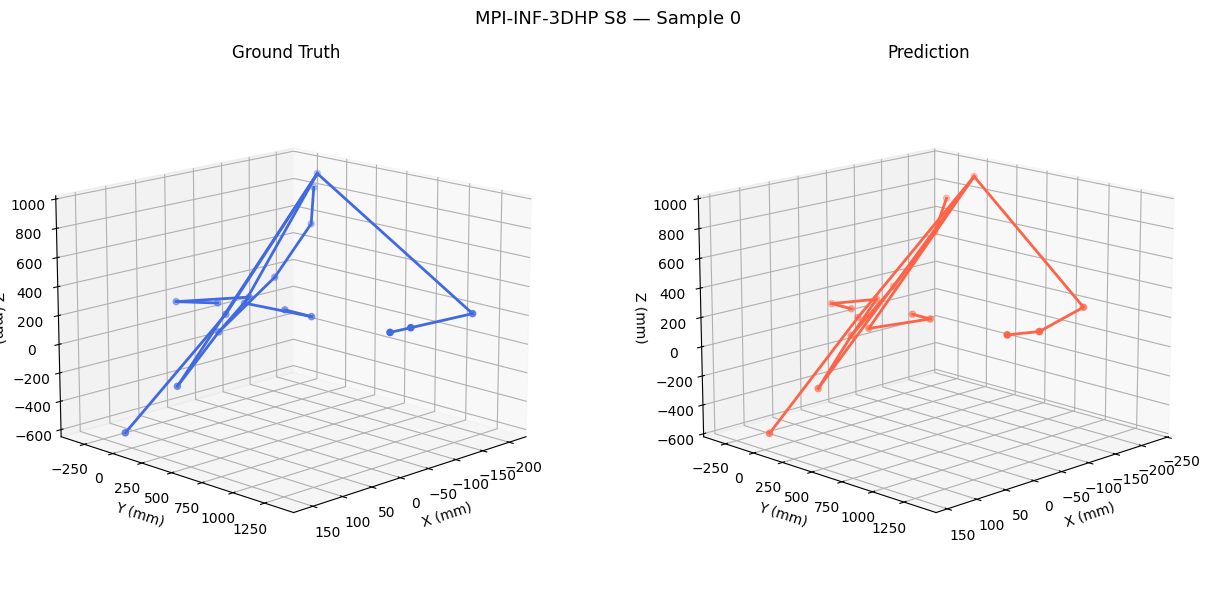

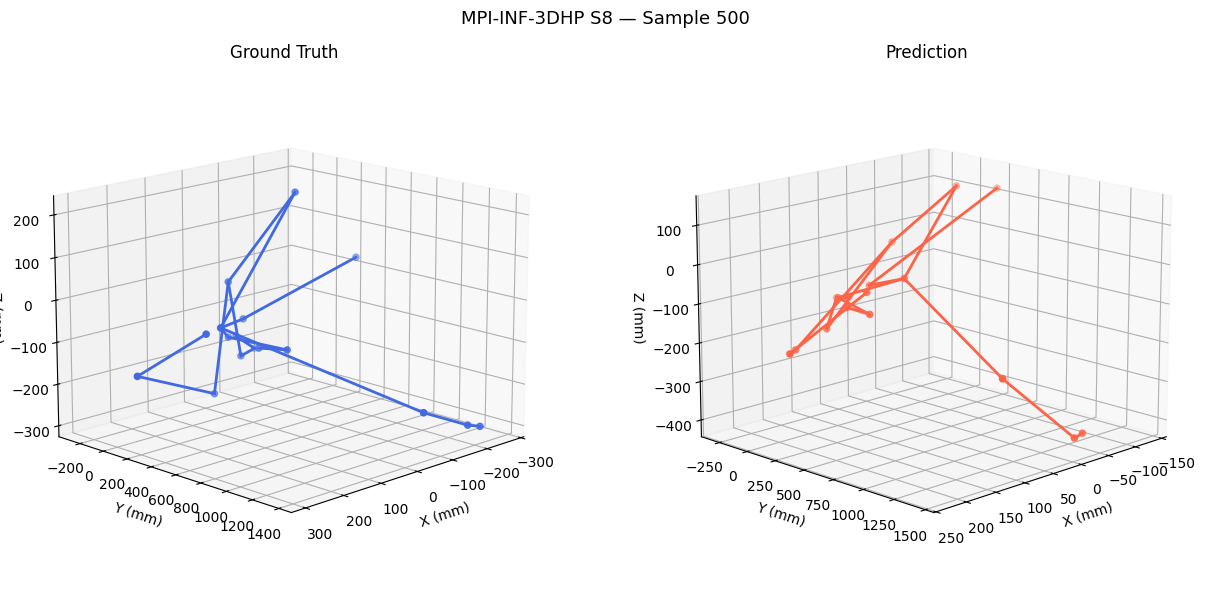

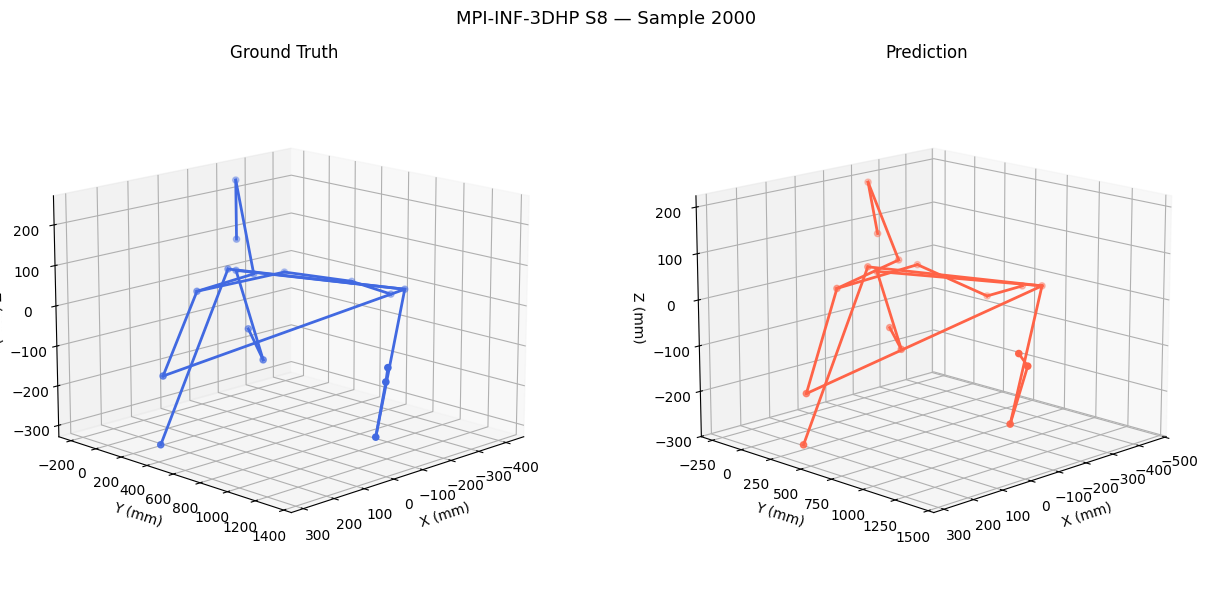

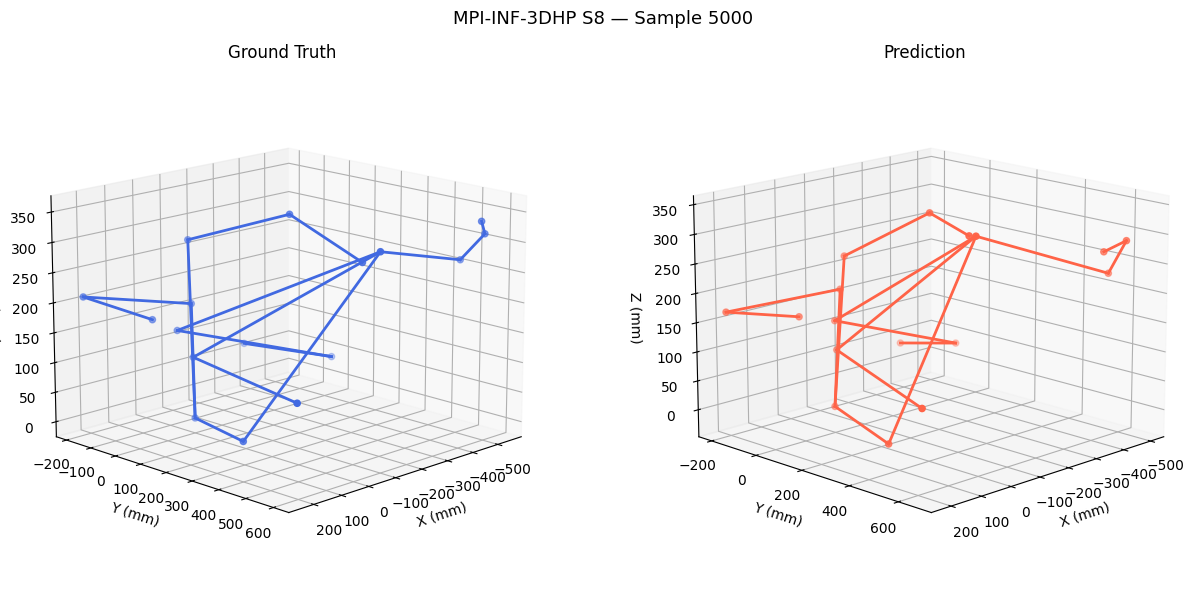

In [11]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

BONES = [
    (0,1),(1,2),(2,3),
    (0,4),(4,5),(5,6),
    (0,7),(7,8),(8,9),(9,10),
    (8,11),(11,12),(12,13),
    (8,14),(14,15),(15,16)
]

def plot_pose(dataset, model, index=0, title=""):
    model.eval()
    X, Y = dataset[index]
    with torch.no_grad():
        pred = model(X.unsqueeze(0).to(device)).cpu().view(17, 3).numpy()
    gt = Y.view(17, 3).numpy()

    fig = plt.figure(figsize=(13, 6))
    fig.suptitle(title or f"Sample index {index}", fontsize=13)

    for col, (data, label, color) in enumerate([(gt, 'Ground Truth', 'royalblue'),
                                                 (pred, 'Prediction',  'tomato')]):
        ax = fig.add_subplot(1, 2, col+1, projection='3d')
        for i, j in BONES:
            ax.plot([data[i,0], data[j,0]],
                    [data[i,1], data[j,1]],
                    [data[i,2], data[j,2]], c=color, linewidth=2)
        ax.scatter(data[:,0], data[:,1], data[:,2], c=color, s=20, zorder=5)
        ax.set_title(label)
        ax.set_xlabel('X (mm)'); ax.set_ylabel('Y (mm)'); ax.set_zlabel('Z (mm)')
        ax.view_init(elev=15, azim=45)

    plt.tight_layout()
    plt.show()

# Plot a few samples from unseen test subject S8
for idx in [0, 500, 2000, 5000]:
    plot_pose(s2_test, final_model, index=idx, title=f"MPI-INF-3DHP S8 — Sample {idx}")


In [12]:
# Research summary table
summary = {
    "Metric": [
        "Dataset",
        "Training Subjects",
        "Val Subject",
        "Unseen Test Subject",
        "Total Training Samples",
        "Stage 1 Best Val MPJPE",
        "Stage 2 Final MPJPE (S8)",
        "PCK@150mm",
        "Architecture",
        "Input Size",
        "Output Size",
    ],
    "Value": [
        "MPI-INF-3DHP",
        "S1, S2, S3, S4, S5, S6, S7",
        "S7",
        "S8 (never seen during training)",
        f"{len(s2_train):,}",
        f"{best_val_mpjpe:.2f} mm",
        f"{best_s2_mpjpe:.2f} mm",
        pck_results['PCK@150mm'],
        "Deep Residual MLP (4 ResBlocks, 1024 hidden)",
        "136  (4 cams × 17 joints × 2)",
        "51   (17 joints × 3)",
    ]
}

df_summary = pd.DataFrame(summary)
print("="*60)
print("         FYP FINAL RESULTS — MPI-INF-3DHP")
print("="*60)
print(df_summary.to_string(index=False))
print("="*60)


         FYP FINAL RESULTS — MPI-INF-3DHP
                  Metric                                        Value
                 Dataset                                 MPI-INF-3DHP
       Training Subjects                   S1, S2, S3, S4, S5, S6, S7
             Val Subject                                           S7
     Unseen Test Subject              S8 (never seen during training)
  Total Training Samples                                      119,071
  Stage 1 Best Val MPJPE                                     43.97 mm
Stage 2 Final MPJPE (S8)                                     58.53 mm
               PCK@150mm                                       93.20%
            Architecture Deep Residual MLP (4 ResBlocks, 1024 hidden)
              Input Size                136  (4 cams × 17 joints × 2)
             Output Size                         51   (17 joints × 3)
